# AskAuto — Problem Statement

**Build a conversational analytics assistant over a small SQL database, using an agentic pipeline that shows its work and admits what it doesn't know.**

> **Note on source of truth.** `docs/PROBLEM_STATEMENT.md` is what Claude Code reads and what the build is held to. This notebook is the presentation version. If they disagree, the markdown wins.

In [1]:
from IPython.display import SVG, display

STYLE = """<style>
  .bx  { fill:#f6f8fa; stroke:#d0d7de; stroke-width:1; }
  .bxa { fill:#f3f0ff; stroke:#8b7fd4; stroke-width:1; }
  .bxw { fill:#fff8e6; stroke:#d4a72c; stroke-width:1; }
  .th  { font:600 13px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#1f2328; }
  .ts  { font:400 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#656d76; }
  .tl  { font:600 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#8250df;
         letter-spacing:.06em; }
  .arr { stroke:#656d76; stroke-width:1.4; fill:none; }
  .arrR{ stroke:#d1242f; stroke-width:1.6; fill:none; stroke-dasharray:5 3; }
  .lbl { font:400 10px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#d1242f; }
</style>
<defs>
  <marker id="a" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#656d76" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
  <marker id="ar" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#d1242f" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
</defs>"""

def diagram(body, width=720, height=400):
    """Render a self-contained SVG diagram inline."""
    return SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
               f'height="{height}" viewBox="0 0 {width} {height}">'
               f'{STYLE}{body}</svg>')


## Context

A car dealer group keeps three related tables in a SQL database: dealership locations, a vehicle catalogue, and sales transactions.

Answering a business question today needs someone who can write SQL *and* who knows the local conventions — that "revenue" means price minus discount, that regions are spelled a particular way. That knowledge sits in two people's heads.

**Goal.** An API that takes a plain-English question, works out the right SQL, runs it, and answers in plain English — returning the query alongside the answer so anyone can verify it.

**Users.** General managers and regional directors. Comfortable with business numbers, not with SQL.

## Required behaviour

- Decide whether a question is answerable **before** writing any SQL
- Build prompts from a **queryable metadata store**, not hardcoded schema text
- Return every number with the SQL that produced it, plus any assumptions made
- Resolve business terms like "net revenue" through a glossary, identically every time
- Use exact category values from metadata instead of guessing spellings
- Validate generated SQL before execution; reject anything that isn't a read
- Retry on invalid SQL, using the database error as feedback (max 3)
- Tell an error apart from a query that legitimately returned nothing
- Refuse when the data can't answer, naming what is missing
- Ask for clarification when a question is ambiguous
- Check that every figure in the final answer appears in the results

## The data model

Three tables, a clean star schema. Two dimensions and one fact table. Small enough to inspect by hand, big enough that aggregation means something.

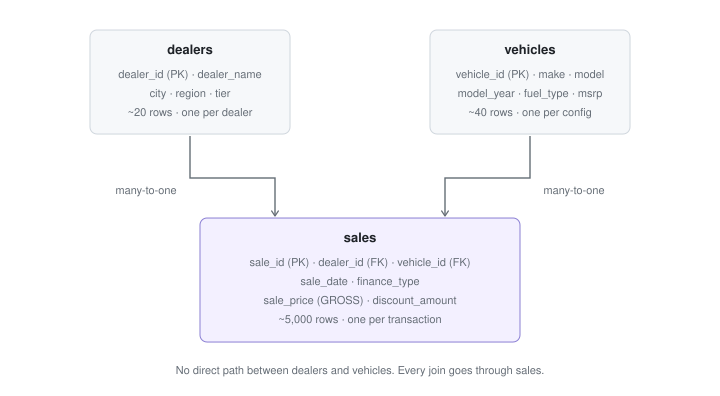

In [2]:
diagram("""
<rect x="90" y="30" width="200" height="104" rx="7" class="bx"/><text class="th" x="190.0" y="54" text-anchor="middle">dealers</text><text class="ts" x="190.0" y="78" text-anchor="middle">dealer_id (PK) · dealer_name</text><text class="ts" x="190.0" y="97" text-anchor="middle">city · region · tier</text><text class="ts" x="190.0" y="116" text-anchor="middle">~20 rows · one per dealer</text>
<rect x="430" y="30" width="200" height="104" rx="7" class="bx"/><text class="th" x="530.0" y="54" text-anchor="middle">vehicles</text><text class="ts" x="530.0" y="78" text-anchor="middle">vehicle_id (PK) · make · model</text><text class="ts" x="530.0" y="97" text-anchor="middle">model_year · fuel_type · msrp</text><text class="ts" x="530.0" y="116" text-anchor="middle">~40 rows · one per config</text>
<rect x="200" y="218" width="320" height="124" rx="7" class="bxa"/><text class="th" x="360.0" y="242" text-anchor="middle">sales</text><text class="ts" x="360.0" y="266" text-anchor="middle">sale_id (PK) · dealer_id (FK) · vehicle_id (FK)</text><text class="ts" x="360.0" y="285" text-anchor="middle">sale_date · finance_type</text><text class="ts" x="360.0" y="304" text-anchor="middle">sale_price (GROSS) · discount_amount</text><text class="ts" x="360.0" y="323" text-anchor="middle">~5,000 rows · one per transaction</text>
<path d="M190 136 L190 178 L275 178 L275 216" class="arr" marker-end="url(#a)"/>
<path d="M530 136 L530 178 L445 178 L445 216" class="arr" marker-end="url(#a)"/>
<text class="ts" x="146" y="194" text-anchor="middle">many-to-one</text>
<text class="ts" x="574" y="194" text-anchor="middle">many-to-one</text>
<text class="ts" x="360" y="374" text-anchor="middle">No direct path between dealers and vehicles. Every join goes through sales.</text>
""", width=720, height=396)

Scale: ~20 dealers, ~40 vehicles, ~5,000 sales. Seeded, so the data is identical on every run and the correct answer to every test question is known.

That determinism is the reason for synthetic data over a real public dataset. It is what makes the evaluation harness possible — with real data you spend an afternoon arguing about what *correct* means and end up measuring vibes.

## The two planted traps

Both are deliberate, and both share a property that makes them worth teaching: **they produce wrong answers that look right.** Nothing throws an error. Nobody notices by eye.

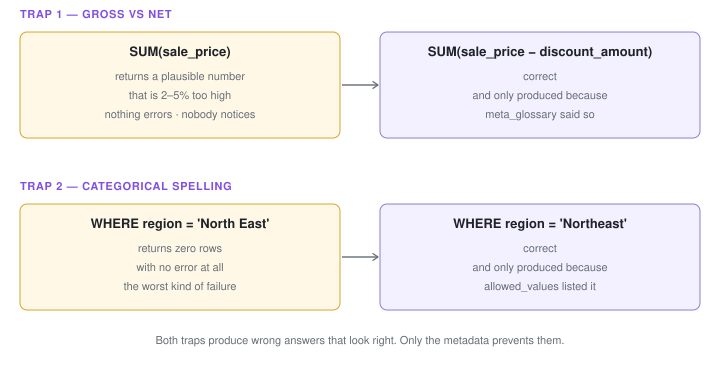

In [3]:
diagram("""
<text class="tl" x="20" y="18">TRAP 1 — GROSS VS NET</text>
<rect x="20" y="32" width="320" height="106" rx="7" class="bxw"/><text class="th" x="180.0" y="56" text-anchor="middle">SUM(sale_price)</text><text class="ts" x="180.0" y="80" text-anchor="middle">returns a plausible number</text><text class="ts" x="180.0" y="99" text-anchor="middle">that is 2–5% too high</text><text class="ts" x="180.0" y="118" text-anchor="middle">nothing errors · nobody notices</text>
<rect x="380" y="32" width="320" height="106" rx="7" class="bxa"/><text class="th" x="540.0" y="56" text-anchor="middle">SUM(sale_price − discount_amount)</text><text class="ts" x="540.0" y="80" text-anchor="middle">correct</text><text class="ts" x="540.0" y="99" text-anchor="middle">and only produced because</text><text class="ts" x="540.0" y="118" text-anchor="middle">meta_glossary said so</text>
<line x1="342" y1="85" x2="378" y2="85" class="arr" marker-end="url(#a)"/>

<text class="tl" x="20" y="190">TRAP 2 — CATEGORICAL SPELLING</text>
<rect x="20" y="204" width="320" height="106" rx="7" class="bxw"/><text class="th" x="180.0" y="228" text-anchor="middle">WHERE region = 'North East'</text><text class="ts" x="180.0" y="252" text-anchor="middle">returns zero rows</text><text class="ts" x="180.0" y="271" text-anchor="middle">with no error at all</text><text class="ts" x="180.0" y="290" text-anchor="middle">the worst kind of failure</text>
<rect x="380" y="204" width="320" height="106" rx="7" class="bxa"/><text class="th" x="540.0" y="228" text-anchor="middle">WHERE region = 'Northeast'</text><text class="ts" x="540.0" y="252" text-anchor="middle">correct</text><text class="ts" x="540.0" y="271" text-anchor="middle">and only produced because</text><text class="ts" x="540.0" y="290" text-anchor="middle">allowed_values listed it</text>
<line x1="342" y1="257" x2="378" y2="257" class="arr" marker-end="url(#a)"/>

<text class="ts" x="360" y="344" text-anchor="middle">Both traps produce wrong answers that look right. Only the metadata prevents them.</text>
""", width=720, height=366)

These two traps are the whole argument for hand-written metadata. A schema introspection tool can tell you `sale_price` is a REAL. Only a human can tell you it is the gross figure and that you almost always want it minus the discount.

## The metadata catalogue

Four tables describing the three above. They get filled from two directions, and the split matters more than anything else in the design.

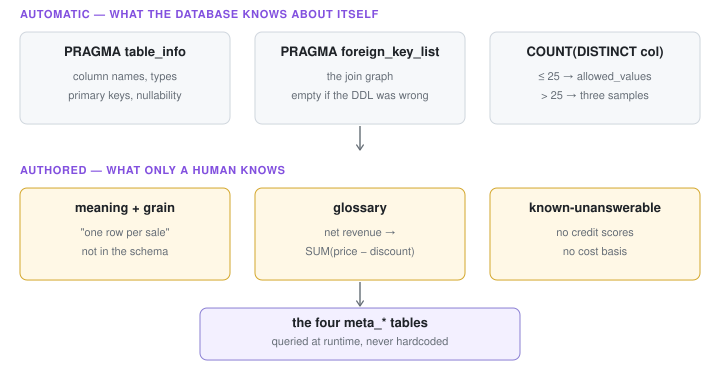

In [4]:
diagram("""
<text class="tl" x="20" y="18">AUTOMATIC — WHAT THE DATABASE KNOWS ABOUT ITSELF</text>
<rect x="20" y="32" width="210" height="92" rx="7" class="bx"/><text class="th" x="125.0" y="56" text-anchor="middle">PRAGMA table_info</text><text class="ts" x="125.0" y="80" text-anchor="middle">column names, types</text><text class="ts" x="125.0" y="99" text-anchor="middle">primary keys, nullability</text>
<rect x="255" y="32" width="210" height="92" rx="7" class="bx"/><text class="th" x="360.0" y="56" text-anchor="middle">PRAGMA foreign_key_list</text><text class="ts" x="360.0" y="80" text-anchor="middle">the join graph</text><text class="ts" x="360.0" y="99" text-anchor="middle">empty if the DDL was wrong</text>
<rect x="490" y="32" width="210" height="92" rx="7" class="bx"/><text class="th" x="595.0" y="56" text-anchor="middle">COUNT(DISTINCT col)</text><text class="ts" x="595.0" y="80" text-anchor="middle">≤ 25 → allowed_values</text><text class="ts" x="595.0" y="99" text-anchor="middle">&gt; 25 → three samples</text>

<text class="tl" x="20" y="174">AUTHORED — WHAT ONLY A HUMAN KNOWS</text>
<rect x="20" y="188" width="210" height="92" rx="7" class="bxw"/><text class="th" x="125.0" y="212" text-anchor="middle">meaning + grain</text><text class="ts" x="125.0" y="236" text-anchor="middle">&quot;one row per sale&quot;</text><text class="ts" x="125.0" y="255" text-anchor="middle">not in the schema</text>
<rect x="255" y="188" width="210" height="92" rx="7" class="bxw"/><text class="th" x="360.0" y="212" text-anchor="middle">glossary</text><text class="ts" x="360.0" y="236" text-anchor="middle">net revenue →</text><text class="ts" x="360.0" y="255" text-anchor="middle">SUM(price − discount)</text>
<rect x="490" y="188" width="210" height="92" rx="7" class="bxw"/><text class="th" x="595.0" y="212" text-anchor="middle">known-unanswerable</text><text class="ts" x="595.0" y="236" text-anchor="middle">no credit scores</text><text class="ts" x="595.0" y="255" text-anchor="middle">no cost basis</text>

<line x1="360" y1="126" x2="360" y2="150" class="arr" marker-end="url(#a)"/>
<line x1="360" y1="282" x2="360" y2="306" class="arr" marker-end="url(#a)"/>
<rect x="200" y="308" width="320" height="52" rx="7" class="bxa"/><text class="th" x="360.0" y="327.0" text-anchor="middle">the four meta_* tables</text><text class="ts" x="360.0" y="345.0" text-anchor="middle">queried at runtime, never hardcoded</text>
""", width=720, height=376)

### The categorical threshold

If a column has 25 or fewer distinct values, store the full list. Otherwise store the count and three samples.

This sounds like a detail and is not. Because the list is stored, the model writes `WHERE region = 'Northeast'` correctly. Without it, it guesses `'North East'`, finds nothing, and reports zero with no error to warn anyone.

### Composite keys

`meta_columns` is keyed on `(table_name, column_name)` and `meta_joins` on all four of its columns. Composite keys appear naturally where they belong, without forcing one into the business tables.

## Deliberately not used

**No vector database, no embeddings.** With three tables the full metadata fits comfortably in one prompt — roughly 1,500 tokens. Semantic schema retrieval would solve a problem this system does not have, and add something else that can break during a demo.

**No multi-agent architecture, no A2A.** One kind of question needs one specialist. A2A solves interop between agents built by different teams in different deployments, which is not a problem here.

This is still legitimately *agentic RAG*. Retrieval is happening — grounding facts are fetched from an external store before answering. The store is SQL rather than a vector index. Embeddings are one retrieval mechanism, not the definition of RAG.

### When vectors would genuinely earn their place

| Situation | Need vectors? |
|---|---|
| 3–10 tables, metadata fits in the prompt | No |
| 50+ tables, metadata blows the context window | Yes |
| 20+ worked SQL examples, want the 3 most similar | Yes — helps even at 3 tables |
| A column contains free text | Yes. The only true vector case |

The `get_schema_context(question)` signature accepts a question from day one, so enabling retrieval later is a config flag rather than a rewrite.

## Growth path

| Stage | Adds | Cost |
|---|---|---|
| 1 | Working single agent | baseline |
| 2 | Vector schema retrieval | config flag, no graph change |
| 3 | Worked-SQL-example retrieval | best return of any embedding work |
| 4 | Free-text column → supervisor + two specialists | the honest multi-agent moment |

## Done when

25 known-answer questions pass — lookups, aggregations, joins, both planted traps, refusals, clarifications — with 100% SQL validity and p95 latency under 8 seconds.

## Out of scope

Authentication, multi-tenancy, write operations, row-level security, real-time ingestion.